# Step 4.1: test the client's rules against the data

**The idea.** The policy (`02`) and the C&F agreement (`03`) contain rules with numbers in them. `notes/rules.md` lists them as R1 to R13.
For each rule we ask: *in the data, how many times was it broken, and how many rupees were involved?*

**What a "breach" means here.** A claim or an invoice that the written rule says should not have been accepted or done, but the data shows it was.
It is a **finding to investigate**, not proof of fraud. The data has no column for exceptions such as an Area Manager's written approval, so some breaches may be approved exceptions we cannot see. We state that every time.

**How to read this notebook.** Each rule has the same five parts: the rule in the client's words (with page), how we test it, the result, a few real rows to check by hand, and the money.
Run top to bottom. Each section ends with a **Check** line.

**Needs:** `pilot/data/` filled by `python -m agent.data --sync ..\data-clean` (Step 3.7). Nothing here changes any data file.

In [1]:
import os, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.join('..', 'pilot'))
from agent.data import load, fy_quarter              # the tested loader from Step 3.7
OUT = os.path.join('..', 'data-clean', 'audit', 'rules'); os.makedirs(OUT, exist_ok=True)

ec = load('expiry_claims').copy(); ps = load('primary_sales'); sku = load('sku_master')
SUMMARY = []        # one line per rule, written to rules_summary.csv at the end
print('claims:', len(ec), '| invoice lines:', len(ps))

claims: 4503 | invoice lines: 93063


## R1. Claim windows (`02` p3 section 5.2)

**The rule, in the client's words.** "A claim received outside its window is rejected. Claims dated more than 90 days after the expiry date are not accepted under any circumstances."

| Claim type | Allowed window |
|---|---|
| Near expiry | from 90 days before expiry to the expiry date |
| Expired | from the expiry date to 90 days after expiry |
| Breakage in transit | within 7 days of the invoice |
| Short supply | within 7 days of the invoice |

**Why it matters.** A claim outside its window becomes a credit note, which is real money and a tax document (`01` Reader's Guide). If the window is not checked, the company pays for returns it had the right to refuse.

**How we test it.**
- *Near expiry and Expired:* days = `claim_date` minus `expiry_date_as_claimed`. Negative means before expiry, positive means after. Compare with the window.
- *Breakage and Short supply:* days = `claim_date` minus the date of the invoice named in `original_invoice_ref`. We can only do this when the claim quotes an invoice that we find in `primary_sales`.

In [2]:
ec['days_from_expiry'] = (ec.claim_date - ec.expiry_date_as_claimed).dt.days     # negative = before expiry
inv_date = ps.groupby('invoice_no').invoice_date.min()
ec['invoice_date_ref'] = ec.original_invoice_ref.map(inv_date)
ec['days_from_invoice'] = (ec.claim_date - ec.invoice_date_ref).dt.days

ne, ex = ec.claim_type.eq('Near expiry'), ec.claim_type.eq('Expired')
bs = ec.claim_type.isin(['Breakage in transit', 'Short supply'])

reason = pd.Series(pd.NA, index=ec.index, dtype='object')
d = ec.days_from_expiry
reason[ne & (d < -90)] = 'Near expiry: filed more than 90 days before expiry'
reason[ne & (d > 90)]  = 'Near expiry: filed more than 90 days after expiry (never accepted)'
reason[ne & (d > 0) & (d <= 90)] = 'Near expiry: filed after expiry (should have been an Expired claim)'
reason[ex & (d > 90)]  = 'Expired: filed more than 90 days after expiry (never accepted)'
reason[ex & (d < 0)]   = 'Expired: filed before expiry'
reason[bs & (ec.days_from_invoice > 7)] = 'Breakage / Short supply: filed more than 7 days after the invoice'
reason[bs & (ec.days_from_invoice < 0)] = 'Breakage / Short supply: filed before the invoice'
ec['r1_reason'] = reason
ec['r1_testable'] = ne | ex | (bs & ec.invoice_date_ref.notna())
ec['r1_breach'] = ec.r1_reason.notna()

# money at issue: a Credited claim has been paid (credit_value_inr); a Pending one can still be stopped (derived claim value)
ec['r1_inr'] = np.where(ec.status.eq('Credited'), ec.credit_value_inr.fillna(0), np.where(ec.status.eq('Pending'), ec.claim_value_derived_inr, 0.0))
print('claims we can test against R1:', int(ec.r1_testable.sum()), 'of', len(ec))
print('   not testable (breakage / short supply with no invoice reference):', int((~ec.r1_testable).sum()))
print('claims that break R1:', int(ec.r1_breach.sum()))

claims we can test against R1: 4428 of 4503
   not testable (breakage / short supply with no invoice reference): 75
claims that break R1: 519


**Check:** testable **4,428** of 4,503; not testable **75** (breakage or short-supply claims that quote no invoice, so we cannot know the invoice date); claims that break R1: **519**.

In [3]:
t = ec[ec.r1_testable]
tab = pd.crosstab(t.claim_type, t.r1_breach.map({True: 'breach', False: 'inside window'}), margins=True)
tab['% breach'] = (tab.get('breach', 0) / tab['All'] * 100).round(1)
tab

r1_breach,breach,inside window,All,% breach
claim_type,,,,
Breakage in transit,106,29,135,78.5
Expired,46,1447,1493,3.1
Near expiry,241,2395,2636,9.1
Short supply,126,38,164,76.8
All,519,3909,4428,11.7


In [4]:
by = ec[ec.r1_breach].groupby(['r1_reason', 'status']).agg(claims=('claim_no', 'size'), inr=('r1_inr', 'sum')).round(0)
by

claims        inr
r1_reason                                          status                     
Breakage / Short supply: filed more than 7 days... Credited     215   925232.0
                                                   Pending       17    55579.0
Expired: filed more than 90 days after expiry (... Credited      35   633750.0
                                                   Pending       10   290888.0
                                                   Rejected       1        0.0
Near expiry: filed after expiry (should have be... Credited      19   391746.0
                                                   Pending       16   558627.0
                                                   Rejected      10        0.0
Near expiry: filed more than 90 days after expi... Credited      29   435561.0
                                                   Pending        6    81344.0
Near expiry: filed more than 90 days before expiry Credited     148  2424779.0
                                                   Pending       13   239454.0

### Picture: when were claims filed, relative to expiry?
Each bar counts claims by days from expiry. The shaded band is the allowed window. Anything outside the band is a breach.

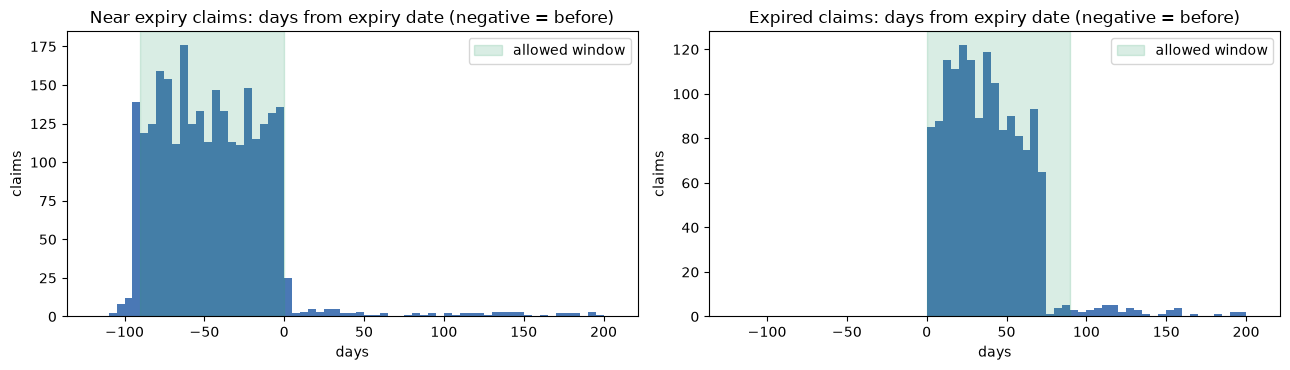

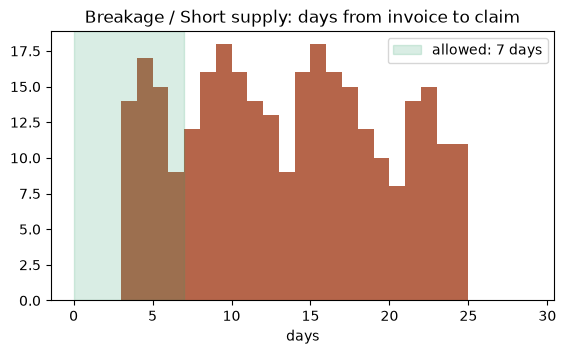

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a, (name, m, lo, hi) in zip(ax, [('Near expiry', ne, -90, 0), ('Expired', ex, 0, 90)]):
    a.hist(ec.loc[m, 'days_from_expiry'], bins=range(-120, 210, 5), color='#4a78b5')
    a.axvspan(lo, hi, color='#2e9e6b', alpha=.18, label='allowed window')
    a.set_title(f'{name} claims: days from expiry date (negative = before)'); a.set_xlabel('days'); a.set_ylabel('claims'); a.legend()
plt.tight_layout(); plt.show()
fig, a = plt.subplots(figsize=(6.5, 3.5))
g = ec.loc[bs & ec.invoice_date_ref.notna(), 'days_from_invoice']
a.hist(g, bins=range(0, 30, 1), color='#b5654a'); a.axvspan(0, 7, color='#2e9e6b', alpha=.18, label='allowed: 7 days')
a.set_title('Breakage / Short supply: days from invoice to claim'); a.set_xlabel('days'); a.legend(); plt.show()

**Read the breakage chart with care.** About 77% of breakage and short-supply claims are filed more than 7 days after the invoice (most 8 to 18 days). A rule broken that often is either not being applied, or is measured differently in practice (for example from the date the goods were received, not invoiced). We report it as a finding but mark it **lower confidence** until the client confirms how the 7 days are counted.

**Check:** the Near expiry chart has a visible block of claims left of the −90 line and a smaller block right of 0. The Expired chart has a block right of 90. The breakage chart has most claims to the right of the 7-day band.

### Is it a few days late, or far outside? (sensitivity)
If most breaches were 1 or 2 days outside, staff might simply be counting months, not days. We count how many remain breaches if we forgive up to N days.

In [6]:
def outside_by(row_d, lo, hi): return np.maximum(lo - row_d, row_d - hi)       # days outside the allowed band (0 = inside)
sens = []
ne_out = outside_by(ec.loc[ne, 'days_from_expiry'], -90, 0); ex_out = outside_by(ec.loc[ex, 'days_from_expiry'], 0, 90)
bs_out = outside_by(ec.loc[bs & ec.invoice_date_ref.notna(), 'days_from_invoice'], 0, 7)
for grace in [0, 3, 5, 7, 14]:
    sens.append({'days forgiven': grace, 'Near expiry': int((ne_out > grace).sum()), 'Expired': int((ex_out > grace).sum()), 'Breakage / Short supply': int((bs_out > grace).sum())})
pd.DataFrame(sens).set_index('days forgiven')

,Near expiry,Expired,Breakage / Short supply
days forgiven,,,
0,241,46,232
3,146,44,182
5,96,43,155
7,90,41,130
14,71,38,37


**Check:** 0 days forgiven gives **241 / 46 / 232**; 14 days forgiven gives **71 / 38 / 37**.

**Reading it.** Many Near-expiry and Breakage breaches are small misses of a few days, which could be counting differences. What stays after 14 days forgiven (71 Near expiry, 38 Expired, 37 Breakage or Short supply) is a clear breach. The Expired breaches barely fall: they are claims filed long after the 90-day limit, which the policy says are never accepted.

### Check by hand: five real breaching claims
Open `data-pack/data/expiry_claims.csv` in VS Code, press **Ctrl+G**, type the `src_row`, and confirm the dates yourself. (Open it read-only; never save it.)

In [7]:
cols = ['src_row', 'claim_no', 'claim_type', 'status', 'claim_date', 'expiry_date_as_claimed', 'invoice_date_ref', 'days_from_expiry', 'days_from_invoice', 'r1_reason', 'r1_inr']
ex_rows = ec[ec.r1_breach].groupby('r1_reason').head(1)[cols].sort_values('r1_reason')
ex_rows

,src_row,claim_no,claim_type,status,claim_date,expiry_date_as_claimed,invoice_date_ref,days_from_expiry,days_from_invoice,r1_reason,r1_inr
2,4,CLM-2404-04044,Short supply,Credited,2024-04-23,2025-09-30,2024-04-08,-525,15.0,Breakage / Short supply: filed more than 7 day...,2027.3
1776,1785,CLM-2505-00135,Expired,Credited,2025-07-21,2025-03-31,2024-05-20,112,427.0,Expired: filed more than 90 days after expiry ...,10333.4
1371,1377,CLM-2505-04432,Near expiry,Credited,2025-05-01,2025-04-30,2024-08-03,1,271.0,Near expiry: filed after expiry (should have b...,10732.8
2112,2122,CLM-2502-00419,Near expiry,Credited,2025-09-21,2025-03-31,2024-06-03,174,475.0,Near expiry: filed more than 90 days after exp...,13343.8
104,106,CLM-2407-03351,Near expiry,Credited,2024-07-20,2024-10-31,NaT,-103,NaN,Near expiry: filed more than 90 days before ex...,453.7


In [8]:
# The claim NUMBER carries a month (CLM-yymm-nnnnn, 03 p3 s2.6 'log every claim when it arrives'). For some claims it is EARLIER than the claim_date.
# If the number's month is the real receipt month, the claim may be inside its window. We keep the breach, but mark how sure we are.
num_start = pd.to_datetime('20' + ec.claim_no.str.slice(4, 8), format='%Y%m'); num_end = num_start + pd.offsets.MonthEnd(0)
ec['date_conflict'] = ec.claim_date.dt.to_period('M') != num_start.dt.to_period('M')
_x = ec.expiry_date_as_claimed
_lo = _x.where(~ne, _x - pd.Timedelta(days=90)); _hi = _x.where(~ex, _x + pd.Timedelta(days=90)).where(~ne, _x)
ec['num_month_in_window'] = (num_start <= _hi) & (num_end >= _lo) & (ne | ex)
ec['r1_confidence'] = np.where(~ec.r1_breach, '', np.where(ec.date_conflict & ec.num_month_in_window, 'depends on which date is right', 'clear'))
dep = ec[ec.r1_breach & ec.r1_confidence.eq('depends on which date is right')]
print(f"R1 breaches that are clear: {int((ec.r1_confidence == 'clear').sum())}; that depend on which date is right (claim number month would be inside the window): {len(dep)}")
keep = ['src_row', 'claim_no', 'claim_date', 'date_conflict', 'r1_confidence', 'stockist_code', 'cnf_code', 'sku_code', 'batch_no', 'claim_type', 'status', 'expiry_date_as_claimed',
        'original_invoice_ref', 'invoice_date_ref', 'days_from_expiry', 'days_from_invoice', 'r1_reason', 'claim_value_derived_inr', 'credit_value_inr', 'r1_inr']
ec.loc[ec.r1_breach, keep].to_csv(os.path.join(OUT, 'r1_breaches.csv'), index=False)
cred = ec[ec.r1_breach & ec.status.eq('Credited')]; pend = ec[ec.r1_breach & ec.status.eq('Pending')]
SUMMARY.append(dict(rule='R1', rule_text='Claim windows (02 p3 s5.2)', tested=int(ec.r1_testable.sum()), not_testable=int((~ec.r1_testable).sum()),
                    breaches=int(ec.r1_breach.sum()), credited_claims=len(cred), credited_inr=round(cred.r1_inr.sum()),
                    pending_claims=len(pend), pending_inr=round(pend.r1_inr.sum()),
                    dependent_breaches=len(dep), dependent_credited_inr=round(dep[dep.status.eq('Credited')].r1_inr.sum()), nature='money paid outside the rule', caveat='No approval/exception column in the data; breakage/short claims with no invoice reference cannot be tested; the 7-day breakage rule is broken so often that its counting method needs client confirmation'))
print(f'R1: {len(cred):,} Credited claims outside their window = INR {cred.r1_inr.sum():,.0f}  ({cred.r1_inr.sum() / ec.credit_value_inr.sum() * 100:.1f}% of all credit notes)')
print(f'    {len(pend):,} Pending claims outside their window = INR {pend.r1_inr.sum():,.0f}  (can still be stopped)')
print('rows saved to data-clean/audit/rules/r1_breaches.csv')

R1 breaches that are clear: 438; that depend on which date is right (claim number month would be inside the window): 81
R1: 446 Credited claims outside their window = INR 4,811,067  (6.7% of all credit notes)
    62 Pending claims outside their window = INR 1,225,892  (can still be stopped)
rows saved to data-clean/audit/rules/r1_breaches.csv


### Caution on R1: which date is right?
The claim **number** holds a month: `CLM-yymm-nnnnn` is assigned when the claim arrives (`03` p3 section 2.6). For **84 claims** that month is **earlier** than the month of `claim_date` (by 1 to 9 months, never later). If the number is right, the claim arrived earlier and may be inside its window.
We keep every R1 breach, but mark each one: **clear** (the dates agree, or even the number's month is outside the window) or **depends on which date is right**. Only the clear ones should be put to the client without a caveat. This is also rule **R12** below.

**Check:** the line above says **438 clear** and **81 depend on which date is right** (together 519).

### R1 validate: a second, independent method must give the same counts

In [9]:
# method 2: plain numpy on integer day numbers, no pandas masks
day = lambda s: s.values.astype('datetime64[D]').astype('int64')
cd, xd = day(ec.claim_date), day(ec.expiry_date_as_claimed)
typ = ec.claim_type.values
n_ne = int(((typ == 'Near expiry') & ((cd < xd - 90) | (cd > xd))).sum())
n_ex = int(((typ == 'Expired') & ((cd < xd) | (cd > xd + 90))).sum())
has = ec.invoice_date_ref.notna().values
idate = np.where(has, day(ec.invoice_date_ref.fillna(ec.claim_date)), 0)
n_bs = int((np.isin(typ, ['Breakage in transit', 'Short supply']) & has & ((cd < idate) | (cd > idate + 7))).sum())
assert n_ne + n_ex + n_bs == int(ec.r1_breach.sum()), (n_ne, n_ex, n_bs, int(ec.r1_breach.sum()))
assert set(ec.claim_type.unique()) == {'Near expiry', 'Expired', 'Breakage in transit', 'Short supply'}      # no type we forgot (BED does not occur)
assert (ec.r1_inr[ec.r1_breach & ec.status.eq('Rejected')] == 0).all()                                           # rejected claims cost nothing
assert ec.days_from_expiry.notna().all() and ec.claim_date.notna().all()
print('R1 independent check agrees:', n_ne, 'Near expiry +', n_ex, 'Expired +', n_bs, 'Breakage/Short =', n_ne + n_ex + n_bs)
print('R1 CHECKS PASSED')

R1 independent check agrees: 241 Near expiry + 46 Expired + 232 Breakage/Short = 519
R1 CHECKS PASSED


## R3. Quantity claimed must not exceed the packs invoiced (`02` p3 section 5.5)

**The rule, in the client's words.** "The quantity claimed for a batch must not exceed the packs of that batch that Pfizer invoiced to that stockist, including free packs."

**Why it matters.** A stockist cannot return more packs than it was sold. If the register accepts more, the company credits stock it never supplied.

**How we test it.**
1. For every stockist and batch, add up packs invoiced **plus free packs** in `primary_sales`. Call it *supplied*.
2. For every claim, add up the quantity claimed on that stockist and batch **so far, in claim-date order, leaving out Rejected claims** (they pay nothing). If that running total goes above *supplied*, the claim is a breach, and the packs above the limit are the *excess*.
3. Excess packs x the SKU's PTS = rupees. Credited = paid; Pending = can still be stopped.

**What we can test.** Only claims on batches that are in `batch_master` and were sold to that stockist: the 3,532 claims we could trace in Step 3.4. The 971 claims on older batches cannot be tested, because their sales are outside the extract.

In [10]:
bat = load('batch_master')
sup = ps[ps.batch_no.notna()].groupby(['stockist_code', 'batch_no']).agg(invoiced=('invoiced_qty', 'sum'), free=('free_qty', 'sum')).reset_index()
sup['supplied'] = sup.invoiced + sup.free
r3 = ec[['src_row', 'claim_no', 'claim_date', 'stockist_code', 'sku_code', 'batch_no', 'qty_claimed', 'status', 'claim_type', 'credit_value_inr', 'claim_value_derived_inr']].merge(
        sup[['stockist_code', 'batch_no', 'invoiced', 'free', 'supplied']], on=['stockist_code', 'batch_no'], how='left')
assert len(r3) == len(ec)
r3['pts'] = r3.sku_code.map(sku.set_index('sku_code').pts_inr)
r3['r3_testable'] = r3.batch_no.isin(bat.batch_no) & r3.supplied.notna()

# running total of claimed packs per stockist+batch, in claim-date order, Rejected claims left out
o = r3[r3.r3_testable & r3.status.ne('Rejected')].sort_values(['claim_date', 'src_row']).copy()
o['claimed_so_far'] = o.groupby(['stockist_code', 'batch_no']).qty_claimed.cumsum()
o['excess_packs'] = (o.claimed_so_far - o.supplied).clip(lower=0).clip(upper=o.qty_claimed)
r3 = r3.merge(o[['src_row', 'claimed_so_far', 'excess_packs']], on='src_row', how='left')
r3['excess_packs'] = r3.excess_packs.fillna(0)
r3['r3_breach'] = r3.excess_packs > 0
r3['single_claim_over'] = r3.r3_testable & r3.status.ne('Rejected') & (r3.qty_claimed > r3.supplied)
r3['r3_inr'] = (r3.excess_packs * r3.pts).where(r3.status.isin(['Credited', 'Pending']), 0.0)
print('claims we can test against R3:', int(r3.r3_testable.sum()), 'of', len(r3), '| not testable (older batches):', int((~r3.r3_testable).sum()))
print('claims that break R3 (running total above packs supplied):', int(r3.r3_breach.sum()), '| by status:', r3[r3.r3_breach].status.value_counts().to_dict())
print('   of which one single claim is already bigger than everything supplied:', int(r3.single_claim_over.sum()))
print('   typical claim is small against supply: median claimed', int(r3[r3.r3_testable].qty_claimed.median()), 'packs, median supplied', int(r3[r3.r3_testable].supplied.median()), 'packs')

claims we can test against R3: 3532 of 4503 | not testable (older batches): 971
claims that break R3 (running total above packs supplied): 44 | by status: {'Credited': 40, 'Pending': 4}
   of which one single claim is already bigger than everything supplied: 36
   typical claim is small against supply: median claimed 141 packs, median supplied 1675 packs


**Check:** testable **3,532**, not testable **971**; **44** breaching claims (**40** Credited, **4** Pending), of which **36** are one single claim already bigger than everything supplied.

**Reading it.** R3 is rarely broken and the amounts are small: the median excess is 7 packs. The quantity limit is mostly respected; the control gap is elsewhere (R1, R4, R6).

In [11]:
b3 = r3[r3.r3_breach]
cred3, pend3 = b3[b3.status.eq('Credited')], b3[b3.status.eq('Pending')]
print(f'R3: {len(cred3):,} Credited claims over the supply limit; excess packs {cred3.excess_packs.sum():,.0f} = INR {cred3.r3_inr.sum():,.0f}')
print(f'    {len(pend3):,} Pending claims over the limit; excess packs {pend3.excess_packs.sum():,.0f} = INR {pend3.r3_inr.sum():,.0f}')
print('excess packs per breaching claim:', b3.excess_packs.describe().round(1).to_dict())
b3.sort_values('excess_packs', ascending=False).head(8)[['src_row', 'claim_no', 'claim_type', 'status', 'qty_claimed', 'supplied', 'claimed_so_far', 'excess_packs', 'r3_inr']]

R3: 40 Credited claims over the supply limit; excess packs 2,476 = INR 179,438
    4 Pending claims over the limit; excess packs 23 = INR 2,777
excess packs per breaching claim: {'count': 44.0, 'mean': 56.8, 'std': 102.8, 'min': 2.0, '25%': 4.8, '50%': 7.0, '75%': 10.2, 'max': 339.0}


,src_row,claim_no,claim_type,status,qty_claimed,supplied,claimed_so_far,excess_packs,r3_inr
3189,3206,CLM-2603-02697,Expired,Credited,2055,2049.0,2388.0,339.0,33018.6
1530,1539,CLM-2506-00656,Expired,Credited,335,5591.0,5936.0,335.0,10452.0
1910,1919,CLM-2508-01291,Expired,Credited,318,6120.0,6447.0,318.0,9921.6
1918,1927,CLM-2508-00900,Expired,Credited,261,6120.0,6708.0,261.0,8143.2
2049,2058,CLM-2509-01111,Expired,Credited,257,1527.0,1789.0,257.0,21767.9
2180,2191,CLM-2509-01115,Expired,Credited,213,1354.0,1577.0,213.0,18041.1
1553,1562,CLM-2506-00350,Expired,Credited,196,1875.0,2073.0,196.0,23167.2
3452,3469,CLM-2604-04482,Expired,Credited,159,1178.0,1343.0,159.0,18793.8


**Check by hand (one claim).** Take the top row. In `primary_sales.csv` filter its stockist and batch, add `invoiced_qty` and `free_qty`: you get `supplied`. In `expiry_claims.csv` add the `qty_claimed` of the non-Rejected claims on that stockist and batch up to that claim: you get `claimed_so_far`. If `claimed_so_far` is above `supplied`, the excess is right.

In [12]:
keep3 = ['src_row', 'claim_no', 'claim_date', 'stockist_code', 'sku_code', 'batch_no', 'claim_type', 'status', 'qty_claimed', 'invoiced', 'free', 'supplied', 'claimed_so_far', 'excess_packs', 'pts', 'credit_value_inr', 'r3_inr']
r3.loc[r3.r3_breach, keep3].to_csv(os.path.join(OUT, 'r3_breaches.csv'), index=False)
SUMMARY.append(dict(rule='R3', rule_text='Quantity claimed within packs invoiced incl. free (02 p3 s5.5)', tested=int(r3.r3_testable.sum()), not_testable=int((~r3.r3_testable).sum()),
                    breaches=int(r3.r3_breach.sum()), credited_claims=len(cred3), credited_inr=round(cred3.r3_inr.sum()), pending_claims=len(pend3), pending_inr=round(pend3.r3_inr.sum()),
                    nature='money paid outside the rule (value of the excess packs only)', caveat='Only claims on batches inside batch_master; 971 older-batch claims cannot be tested'))

### R3 validate: a plain Python loop must agree with the pandas result

In [13]:
seen, sup_d, brk = {}, {(a, b): s for a, b, s in zip(sup.stockist_code, sup.batch_no, sup.supplied)}, 0
tot_excess = 0
for row in r3[r3.r3_testable & r3.status.ne('Rejected')].sort_values(['claim_date', 'src_row']).itertuples():
    k = (row.stockist_code, row.batch_no); seen[k] = seen.get(k, 0) + row.qty_claimed
    ex = min(max(seen[k] - sup_d[k], 0), row.qty_claimed)
    if ex > 0: brk += 1; tot_excess += ex
assert brk == int(r3.r3_breach.sum()), (brk, int(r3.r3_breach.sum()))
assert tot_excess == r3.excess_packs.sum()
assert (r3.excess_packs[r3.status.eq('Rejected')] == 0).all() and (r3.r3_inr[~r3.r3_breach] == 0).all()
assert int(r3.r3_testable.sum()) == 3532
print('R3 independent check agrees:', brk, 'breaching claims,', int(tot_excess), 'excess packs')
print('R3 CHECKS PASSED')

R3 independent check agrees: 44 breaching claims, 2499 excess packs
R3 CHECKS PASSED


## R4. No earlier claim on the same stockist and batch (`02` p4 section 5.6; `03` p3 section 2.6)

**The rule, in the client's words.** During verification the C&F must "check for an earlier claim on the same stockist and batch."

**Why it matters.** Two people in Commercial Finance settle all claims and "cannot check claims against sales history. She raised the risk of duplicate claims but did not have a figure" (`06` p4, Item 2). This test gives that figure.

**How we test it.** Put each stockist and batch's claims in date order. A claim is a **repeat** if an earlier claim exists on the same stockist and batch. We then split repeats in two:
- **Probable duplicate:** an earlier claim that was *not* Rejected, for the **same quantity**. Same stockist, same batch, same packs again.
- **Repeat, different quantity:** could be a genuine second part-return. It is not wrong by itself, but R3 checks it does not push the total above what was supplied.

**What the policy does not say.** It does not forbid a second claim; it requires the check. So "repeat" is not a breach on its own. A **probable duplicate that was paid** is the clear breach.

In [14]:
e4 = ec[['src_row', 'claim_no', 'claim_date', 'stockist_code', 'batch_no', 'sku_code', 'qty_claimed', 'claim_type', 'status', 'credit_value_inr', 'claim_value_derived_inr', 'remarks']].sort_values(['claim_date', 'src_row']).copy()
key = ['stockist_code', 'batch_no']
e4['claims_before'] = e4.groupby(key).cumcount()
e4['r4_repeat'] = e4.claims_before > 0
live = e4.status.ne('Rejected').astype(int)
e4['live_before_same_qty'] = live.groupby([e4.stockist_code, e4.batch_no, e4.qty_claimed]).cumsum() - live      # earlier NON-rejected claims, same stockist, batch and quantity
e4['r4_probable_dup'] = e4.live_before_same_qty > 0
e4['r4_inr'] = np.where(e4.status.eq('Credited'), e4.credit_value_inr.fillna(0), np.where(e4.status.eq('Pending'), e4.claim_value_derived_inr, 0.0))
rep = e4[e4.r4_repeat]
print('claims with an earlier claim on the same stockist + batch:', len(rep), '| by status:', rep.status.value_counts().to_dict())
print('stockist+batch pairs claimed more than once:', int((e4.groupby(key).size() > 1).sum()), '| most claims on one batch:', int(e4.groupby(key).size().max()))
print('probable duplicates (same quantity as an earlier live claim):', int(e4.r4_probable_dup.sum()), '| by status:', e4[e4.r4_probable_dup].status.value_counts().to_dict())
print('Rejected claims in total:', int(e4.status.eq('Rejected').sum()), '| of them repeats:', int((e4.status.eq('Rejected') & e4.r4_repeat).sum()), '| remark:', e4[e4.status.eq('Rejected')].remarks.unique().tolist())

claims with an earlier claim on the same stockist + batch: 526 | by status: {'Credited': 445, 'Pending': 50, 'Rejected': 31}
stockist+batch pairs claimed more than once: 456 | most claims on one batch: 5
probable duplicates (same quantity as an earlier live claim): 98 | by status: {'Credited': 61, 'Rejected': 25, 'Pending': 12}
Rejected claims in total: 31 | of them repeats: 31 | remark: ['Duplicate of earlier claim']


**Check:** repeats **526** (445 Credited, 50 Pending, 31 Rejected); **456** pairs claimed more than once; all **31** Rejected claims are repeats with the remark `Duplicate of earlier claim`; probable duplicates (same quantity) **98** = **61** Credited + **12** Pending + **25** Rejected.

In [15]:
pd_ = e4[e4.r4_probable_dup]
cred4, pend4 = pd_[pd_.status.eq('Credited')], pd_[pd_.status.eq('Pending')]
rej4 = pd_[pd_.status.eq('Rejected')]
print(f'Probable duplicates already CREDITED: {len(cred4):,} claims = INR {cred4.r4_inr.sum():,.0f}')
print(f'Probable duplicates still PENDING   : {len(pend4):,} claims = INR {pend4.r4_inr.sum():,.0f}  (can be stopped)')
print(f'Probable duplicates REJECTED        : {len(rej4):,} claims  (the control that worked)')
print(f'Repeats with a different quantity, Credited: {int((e4.r4_repeat & ~e4.r4_probable_dup & e4.status.eq("Credited")).sum()):,} claims = INR {e4[e4.r4_repeat & ~e4.r4_probable_dup & e4.status.eq("Credited")].r4_inr.sum():,.0f}  (not a breach by itself; see R3)')
e4[e4.r4_probable_dup & e4.status.eq('Credited')].sort_values('r4_inr', ascending=False).head(6)[['src_row', 'claim_no', 'claim_date', 'stockist_code', 'batch_no', 'qty_claimed', 'claim_type', 'status', 'r4_inr']]

Probable duplicates already CREDITED: 61 claims = INR 1,114,437
Probable duplicates still PENDING   : 12 claims = INR 345,693  (can be stopped)
Probable duplicates REJECTED        : 25 claims  (the control that worked)
Repeats with a different quantity, Credited: 384 claims = INR 7,023,333  (not a breach by itself; see R3)


,src_row,claim_no,claim_date,stockist_code,batch_no,qty_claimed,claim_type,status,r4_inr
3588,3606,CLM-2605-04466,2026-05-14,STK0108,K2400225,1231,Expired,Credited,175786.8
3072,3089,CLM-2602-04491,2026-02-19,STK0129,H2400224,950,Near expiry,Credited,135660.0
3668,3686,CLM-2605-04442,2026-05-27,STK0086,F2440122,478,Near expiry,Credited,47178.6
2786,2800,CLM-2601-04422,2026-01-05,STK0075,M2330141,260,Expired,Credited,40976.0
3221,3238,CLM-2603-04445,2026-03-14,STK0131,E2430144,228,Near expiry,Credited,35932.8
3681,3699,CLM-2605-04388,2026-05-31,STK0020,C2420264,511,Expired,Credited,31579.8


**Check by hand.** Take one row. In `expiry_claims.csv` search its `stockist_code` and `batch_no` together: you should find an earlier claim with the **same quantity** that is not Rejected. If you do, it is a duplicate claim that was paid.

In [16]:
k4 = ['src_row', 'claim_no', 'claim_date', 'stockist_code', 'batch_no', 'sku_code', 'qty_claimed', 'claim_type', 'status', 'claims_before', 'live_before_same_qty', 'r4_repeat', 'r4_probable_dup', 'credit_value_inr', 'r4_inr']
e4.loc[e4.r4_repeat, k4].to_csv(os.path.join(OUT, 'r4_repeat_claims.csv'), index=False)
SUMMARY.append(dict(rule='R4', rule_text='No earlier claim on the same stockist and batch (02 p4 s5.6)', tested=len(e4), not_testable=0,
                    breaches=int(e4.r4_probable_dup.sum()), credited_claims=len(cred4), credited_inr=round(cred4.r4_inr.sum()), pending_claims=len(pend4), pending_inr=round(pend4.r4_inr.sum()),
                    nature='money paid outside the rule (probable duplicates; whole claim value)', caveat='A repeat with a different quantity may be a genuine part-return, so only same-quantity repeats are counted as breaches; breaches count includes the Rejected duplicates the control caught'))

### R4 validate: a plain Python loop must agree

In [17]:
hist, dup, rep_n = {}, 0, 0
for r in e4.itertuples():
    k = (r.stockist_code, r.batch_no); h = hist.setdefault(k, [])
    if h: rep_n += 1
    if any((q == r.qty_claimed and st != 'Rejected') for q, st in h): dup += 1
    h.append((r.qty_claimed, r.status))
assert rep_n == int(e4.r4_repeat.sum()) and dup == int(e4.r4_probable_dup.sum()), (rep_n, dup)
assert (e4[e4.status.eq('Rejected')].r4_inr == 0).all()
assert len(e4) == len(ec) and e4.src_row.is_unique
print('R4 independent check agrees:', rep_n, 'repeats,', dup, 'probable duplicates')
print('R4 CHECKS PASSED')

R4 independent check agrees: 526 repeats, 98 probable duplicates
R4 CHECKS PASSED


## R6. Credit note within 30 days of receiving the claim (`02` p4 section 5.6)

**The rule, in the client's words.** Commercial Finance must "approve and raise the credit note" within **30 days from receipt of the claim**. The C&F must also do physical verification within **10 working days**.

**Why it matters.** The QBR reports the average at 46 days against a 30-day policy (`06` p1) and the Controller asked for a plan to clear the backlog (action A5). A late credit note keeps the stockist's money tied up and generates the chasing emails in the inbox.

**How we test it.** The claims register logs a claim on receipt (`02` §5.6), so `claim_date` is the receipt date. Days = `credit_note_date` minus `claim_date`. For claims still **Pending**, we count their age to **30 Sep 2026**, the end of the extract (`01` p3 section 5).

**What we cannot test.** The 10-working-day verification: the data has `verified_by` but no verification date.

**Important.** This is a **service-level breach, not money lost**. We size it as the value of credit notes that were late, and as rupee-days beyond the limit.

In [18]:
cn = ec[ec.credit_note_date.notna()].copy()
cn['days_to_cn'] = (cn.credit_note_date - cn.claim_date).dt.days
cn['late_days'] = (cn.days_to_cn - 30).clip(lower=0)
late = cn[cn.days_to_cn > 30]
ASOF = pd.Timestamp('2026-09-30')
pen = ec[ec.status.eq('Pending')].copy(); pen['age'] = (ASOF - pen.claim_date).dt.days; pen_late = pen[pen.age > 30]
print(f'credit notes issued: {len(cn):,} | on time (30 days or less): {len(cn) - len(late):,} | LATE: {len(late):,} ({len(late) / len(cn) * 100:.1f}%)')
print(f'days from claim to credit note: mean {cn.days_to_cn.mean():.1f}, median {cn.days_to_cn.median():.0f}, 90th percentile {cn.days_to_cn.quantile(.9):.0f}, longest {cn.days_to_cn.max()}')
print(f'value of LATE credit notes: INR {late.credit_value_inr.sum():,.0f} of INR {cn.credit_value_inr.sum():,.0f} issued ({late.credit_value_inr.sum() / cn.credit_value_inr.sum() * 100:.1f}%)')
print(f'rupee-days beyond 30 days: INR {(late.credit_value_inr * late.late_days).sum():,.0f} rupee-days (the same as holding INR {(late.credit_value_inr * late.late_days).sum() / 365:,.0f} for one year)')
print(f'PENDING claims: {len(pen):,} (INR {pen.claim_value_derived_inr.sum():,.0f}); older than 30 days at {ASOF.date()}: {len(pen_late):,} (INR {pen_late.claim_value_derived_inr.sum():,.0f}); oldest {int(pen.age.max())} days')
print('credit notes dated before the claim:', int((cn.days_to_cn < 0).sum()))
print()
print(cn.groupby('cnf_code').days_to_cn.agg(mean='mean', median='median', late_share=lambda s: (s > 30).mean()).round(2).join(cn.groupby('cnf_code').size().rename('credit_notes')))

credit notes issued: 4,112 | on time (30 days or less): 997 | LATE: 3,115 (75.8%)
days from claim to credit note: mean 45.2, median 42, 90th percentile 72, longest 183
value of LATE credit notes: INR 54,125,894 of INR 71,598,025 issued (75.6%)
rupee-days beyond 30 days: INR 1,143,735,900 rupee-days (the same as holding INR 3,133,523 for one year)
PENDING claims: 360 (INR 9,594,792); older than 30 days at 2026-09-30: 129 (INR 3,378,987); oldest 111 days
credit notes dated before the claim: 0

           mean  median  late_share  credit_notes
cnf_code                                         
CF-E01    47.84    45.0        0.80           651
CF-N01    44.76    42.0        0.74           654
CF-N02    44.30    41.0        0.74           698
CF-S01    45.19    43.0        0.77           665
CF-S02    44.59    42.0        0.76           743
CF-W01    44.58    41.0        0.74           701


**Check:** credit notes **4,112**; LATE **3,115 (75.8%)**; mean **45.2** days, median **42**. Pending **360**, **129** older than 30 days at 30 Sep 2026. No credit note is dated before its claim.

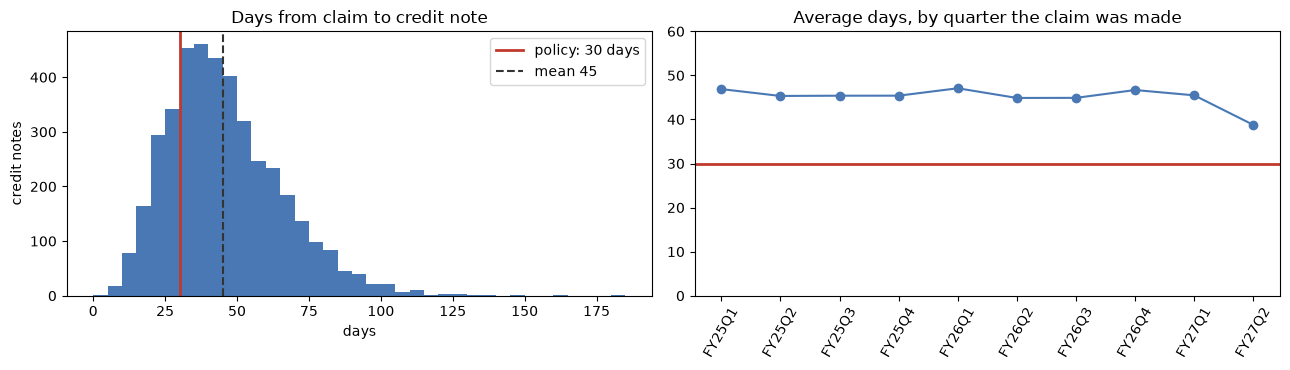

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].hist(cn.days_to_cn, bins=range(0, 190, 5), color='#4a78b5'); ax[0].axvline(30, color='#c0392b', lw=2, label='policy: 30 days'); ax[0].axvline(cn.days_to_cn.mean(), color='#333', ls='--', label=f'mean {cn.days_to_cn.mean():.0f}')
ax[0].set_title('Days from claim to credit note'); ax[0].set_xlabel('days'); ax[0].set_ylabel('credit notes'); ax[0].legend()
q = cn.assign(q=fy_quarter(cn.claim_date)).groupby('q').days_to_cn.mean()
ax[1].plot(q.index, q.values, marker='o', color='#4a78b5'); ax[1].axhline(30, color='#c0392b', lw=2); ax[1].set_title('Average days, by quarter the claim was made'); ax[1].tick_params(axis='x', rotation=60); ax[1].set_ylim(0, 60)
plt.tight_layout(); plt.show()

**Check:** the left chart has almost all of its bars to the right of the red line; the right chart sits well above the red line in every quarter.

In [20]:
kc = ['src_row', 'claim_no', 'claim_date', 'cnf_code', 'status', 'credit_note_no', 'credit_note_date', 'days_to_cn', 'late_days', 'credit_value_inr']
late[kc].to_csv(os.path.join(OUT, 'r6_late_credit_notes.csv'), index=False)
pen_late[['src_row', 'claim_no', 'claim_date', 'cnf_code', 'age', 'claim_value_derived_inr']].to_csv(os.path.join(OUT, 'r6_pending_over_30_days.csv'), index=False)
SUMMARY.append(dict(rule='R6', rule_text='Credit note within 30 days of receipt (02 p4 s5.6)', tested=len(cn) + len(pen), not_testable=0,
                    breaches=len(late) + len(pen_late), credited_claims=len(late), credited_inr=round(late.credit_value_inr.sum()), pending_claims=len(pen_late), pending_inr=round(pen_late.claim_value_derived_inr.sum()),
                    nature='service delay, not a money loss (value of late credit notes)', caveat='claim_date used as the date of receipt; pending age counted to 30 Sep 2026; 10-working-day verification cannot be tested (no verification date)'))

### R6 validate: second method with numpy, plus the QBR's own turnaround number

In [21]:
a = ec.credit_note_date.values.astype('datetime64[D]').astype('int64'); b = ec.claim_date.values.astype('datetime64[D]').astype('int64')
has = ec.credit_note_date.notna().values
d_ = (a - b)[has]
assert int((d_ > 30).sum()) == len(late) and int(has.sum()) == len(cn)
assert (ec.status.eq('Credited') == has).all()                     # a credit note exists exactly when the claim is Credited
assert len(pen) == 360 and int((pen.age < 0).sum()) == 0
# the QBR scorecard (06 p1): average 46 days for claims credited in Q1 FY27, 3.6 reconciled it already
qcn = cn.assign(q=fy_quarter(cn.credit_note_date)).groupby('q').days_to_cn.mean()
assert round(qcn['FY27Q1']) == 46
print('R6 independent check agrees:', int((d_ > 30).sum()), 'late credit notes; Q1 FY27 average', round(qcn['FY27Q1'], 1), 'days = QBR 46')
print('R6 CHECKS PASSED')

R6 independent check agrees: 3115 late credit notes; Q1 FY27 average 45.7 days = QBR 46
R6 CHECKS PASSED


## R2. An invoice reference is required, or the Area Manager approves in writing (`02` p3 sections 5.3 and 5.4)

**The rule.** A valid claim contains "the original Pfizer invoice number on which the stock was supplied". Where the stockist cannot quote it, the C&F may verify against the stockist's purchase ledger "with written approval from the Area Manager. (Added in v4.2.)"

**Why it matters.** Without the invoice number nobody can check the quantity (R3) or the window (R1) against sales. The approval is the only control left.

**How we test it.** Find claims with a blank `original_invoice_ref`. Then look for evidence of the Area Manager's approval. The register has **no approval column**, so we search the `remarks` text for "Area Manager" or "approval".

**Reading the result.** A blank reference with no recorded approval is **not evidenced**, not proven wrong: the approval may exist on paper. It is the weakest kind of finding and we label it so.

In [22]:
blank = ec.original_invoice_ref.isna()
txt = ec.remarks.fillna('').str.lower()
ec['r2_blank_ref'] = blank
ec['r2_approval_in_remarks'] = txt.str.contains('area manager|approval|approved')
ec['r2_not_evidenced'] = blank & ~ec.r2_approval_in_remarks & ec.status.isin(['Credited', 'Pending'])
ec['r2_inr'] = np.where(ec.status.eq('Credited'), ec.credit_value_inr.fillna(0), np.where(ec.status.eq('Pending'), ec.claim_value_derived_inr, 0.0))
print('claims with a blank invoice reference:', int(blank.sum()), f'({blank.mean() * 100:.1f}% of {len(ec):,})', '| by status:', ec[blank].status.value_counts().to_dict())
print('remarks mentioning an Area Manager or approval, anywhere in the register:', int(ec.r2_approval_in_remarks.sum()))
print('\nwhat the remarks say on blank-reference claims:')
print(ec[blank].remarks.fillna('(none)').value_counts().to_string())

claims with a blank invoice reference: 879 (19.5% of 4,503) | by status: {'Credited': 798, 'Pending': 63, 'Rejected': 18}
remarks mentioning an Area Manager or approval, anywhere in the register: 0

what the remarks say on blank-reference claims:
remarks
Party says invoice misplaced                              285
Inv ref missing, verified on batch                        257
Invoice copy not attached, accepted on stockist ledger    256
(none)                                                     63
Duplicate of earlier claim                                 18


**Check:** **879** blank (19.5%): 798 Credited, 63 Pending, 18 Rejected. **0** remarks mention an Area Manager or approval. The remarks that do appear are 'Party says invoice misplaced', 'Inv ref missing, verified on batch' and 'Invoice copy not attached, accepted on stockist ledger'.

In [23]:
nb2 = ec[ec.r2_not_evidenced]
c2, p2 = nb2[nb2.status.eq('Credited')], nb2[nb2.status.eq('Pending')]
print(f'R2: {len(c2):,} Credited claims with no invoice reference and no recorded approval = INR {c2.r2_inr.sum():,.0f}  ({c2.r2_inr.sum() / ec.credit_value_inr.sum() * 100:.1f}% of all credit notes)')
print(f'    {len(p2):,} Pending claims in the same position = INR {p2.r2_inr.sum():,.0f}')
by_t = nb2.groupby('claim_type').agg(claims=('claim_no', 'size'), inr=('r2_inr', 'sum')).round(0); by_t

R2: 798 Credited claims with no invoice reference and no recorded approval = INR 13,274,550  (18.5% of all credit notes)
    63 Pending claims in the same position = INR 1,434,690


,claims,inr
claim_type,,
Breakage in transit,47,185975.0
Expired,291,5487325.0
Near expiry,495,8909149.0
Short supply,28,126792.0


In [24]:
nb2[['src_row', 'claim_no', 'claim_date', 'stockist_code', 'cnf_code', 'claim_type', 'status', 'verified_by', 'remarks', 'r2_inr']].to_csv(os.path.join(OUT, 'r2_no_invoice_no_approval.csv'), index=False)
SUMMARY.append(dict(rule='R2', rule_text='Invoice reference or Area Manager approval (02 p3 s5.3-5.4)', tested=len(ec), not_testable=0, breaches=len(nb2), credited_claims=len(c2), credited_inr=round(c2.r2_inr.sum()),
                    pending_claims=len(p2), pending_inr=round(p2.r2_inr.sum()), nature='approval not evidenced (weakest kind of finding: the approval may exist on paper)',
                    caveat='The register has no approval column; only the remarks text was searched'))

**Check by hand.** Open `data-clean/audit/rules/r2_no_invoice_no_approval.csv`, take any `src_row`, press Ctrl+G on `expiry_claims.csv` and confirm the `original_invoice_ref` cell is empty and `remarks` has no approval.

In [25]:
assert int(ec.original_invoice_ref.isna().sum()) == sum(1 for v in ec.original_invoice_ref if pd.isna(v))
assert len(nb2) == sum(1 for r in ec.itertuples() if pd.isna(r.original_invoice_ref) and r.status in ('Credited', 'Pending') and not any(w in str(r.remarks).lower() for w in ('area manager', 'approval', 'approved')))
assert (ec.invoice_ref_missing == ec.r2_blank_ref).all()                      # same as the flag from the cleaning notebook
print('R2 CHECKS PASSED:', len(nb2), 'claims without a reference or recorded approval')

R2 CHECKS PASSED: 861 claims without a reference or recorded approval


## R5. Claims are valued at PTS (`02` p4 section 5.7)

**The rule.** "Claims are valued at the PTS in force on the date of the claim."

**How we test it.**
1. Is every recorded `claim_value_inr` equal to `qty_claimed` x the SKU's PTS?
2. Is every credit note (`credit_value_inr`) equal to the claim value?

**What we cannot test.** "PTS on the claim date": the extract has **one price per SKU** (`01` p3 section 5.1), so we cannot see if a price changed. This is a limit, not a finding.

In [26]:
pts5 = ec.sku_code.map(sku.set_index('sku_code').pts_inr)
rec = ec.claim_value_inr.notna()
print('recorded claim values:', int(rec.sum()), '| equal to qty x PTS:', int(((ec.qty_claimed * pts5 - ec.claim_value_inr).abs()[rec] < 0.01).sum()))
cr5 = ec[ec.status.eq('Credited')].copy()
cr5['gap'] = cr5.claim_value_derived_inr - cr5.credit_value_inr
low = cr5[cr5.gap.abs() > 0.01]
print(f'credit notes issued: {len(cr5):,} | equal to the claim value: {len(cr5) - len(low):,} | different: {len(low):,}')
print(f'   lower than the claim: {int((low.gap > 0).sum()):,} | higher than the claim: {int((low.gap < 0).sum()):,}')
print(f'   total shortfall (claim value minus credit value): INR {low.gap.sum():,.0f} | credit is {(low.credit_value_inr / low.claim_value_derived_inr).min() * 100:.0f}% to {(low.credit_value_inr / low.claim_value_derived_inr).max() * 100:.0f}% of the claim value')
print('Pending or Rejected claims with a credit value:', int(ec[~ec.status.eq('Credited')].credit_value_inr.notna().sum()))
low.assign(credit_pct=(low.credit_value_inr / low.claim_value_derived_inr * 100).round(1)).sort_values('gap', ascending=False).head(5)[['src_row', 'claim_no', 'claim_type', 'qty_claimed', 'claim_value_derived_inr', 'credit_value_inr', 'credit_pct', 'remarks']]

recorded claim values: 4368 | equal to qty x PTS: 4368
credit notes issued: 4,112 | equal to the claim value: 3,785 | different: 327
   lower than the claim: 327 | higher than the claim: 0
   total shortfall (claim value minus credit value): INR 458,441 | credit is 85% to 99% of the claim value
Pending or Rejected claims with a credit value: 0


,src_row,claim_no,claim_type,qty_claimed,claim_value_derived_inr,credit_value_inr,credit_pct,remarks
3521,3538,CLM-2605-01577,Near expiry,1824,287462.4,245097.91,85.3,Physical verification done
3368,3385,CLM-2604-02949,Near expiry,6184,192940.8,173125.71,89.7,"Inv ref missing, verified on batch"
2130,2140,CLM-2509-01249,Expired,927,132375.6,114070.21,86.2,"Inv ref missing, verified on batch"
3391,3408,CLM-2604-01891,Expired,1277,114036.1,99911.05,87.6,NaN
3271,3288,CLM-2603-01712,Near expiry,594,76329.0,65012.59,85.2,Verified


**Check:** recorded values **4,368 of 4,368** equal qty x PTS. Credit notes **4,112**; **327** differ, all **lower** (85% to 99% of the claim), total shortfall about **INR 4.58 lakh**; none higher.

**Reading it.** The company credited **less** than the claim, so this is not a cost to the company. No column explains the reduction, so we cannot say if it is a deduction for damaged stock or a valuation inconsistency. It is a small amount, and a question for the client.

In [27]:
low[['src_row', 'claim_no', 'claim_date', 'claim_type', 'qty_claimed', 'claim_value_derived_inr', 'credit_value_inr', 'gap', 'remarks']].to_csv(os.path.join(OUT, 'r5_credit_below_claim.csv'), index=False)
SUMMARY.append(dict(rule='R5', rule_text='Claims valued at PTS (02 p4 s5.7)', tested=len(cr5), not_testable=0, breaches=len(low), credited_claims=len(low), credited_inr=round(low.gap.sum()), pending_claims=0, pending_inr=0,
                    nature='valuation difference: credit note is LOWER than the claim (the company paid less)', caveat='PTS on the claim date cannot be tested (one price per SKU in the extract); the reason for the lower credit is not in the data'))
assert ((ec.qty_claimed * pts5 - ec.claim_value_inr).abs()[rec] < 0.01).all()
assert (low.gap > 0).all()
print('R5 CHECKS PASSED')

R5 CHECKS PASSED


## R7. Minimum remaining shelf life at dispatch (`02` p4 section 7.1; `03` p3 section 2.3)

**The rule.** "Stock billed to a stockist must have RSL of at least 60% of total shelf life on the invoice date." Also: "CFAs must not dispatch stock with less than 60 days to expiry."

**How we test it.** For each invoice line with a batch: remaining life = batch expiry (from `batch_master`) minus invoice date. Total shelf life = `shelf_life_months` x 30.4375 days (`sku_master`). Breach if remaining life is under 60% of that, or under 60 days. We also test a second way: remaining life divided by the batch's own life (expiry minus manufacture date).

**Why it matters.** Short-dated stock sent out is the source of near-expiry claims later.

In [28]:
bm = load('batch_master').set_index('batch_no')
p7 = ps[ps.batch_no.notna()].copy()
p7['expiry'] = p7.batch_no.map(bm.expiry_date); p7['mfg'] = p7.batch_no.map(bm.mfg_date); p7['shelf_m'] = p7.sku_code.map(sku.set_index('sku_code').shelf_life_months)
p7['days_left'] = (p7.expiry - p7.invoice_date).dt.days
p7['rsl'] = p7.days_left / (p7.shelf_m * 30.4375)
p7['rsl_batch'] = p7.days_left / (p7.expiry - p7.mfg).dt.days
p7['r7_breach'] = (p7.rsl < 0.60) | (p7.days_left < 60)
p7['qtr'] = fy_quarter(p7.invoice_date)
b7 = p7[p7.r7_breach]
print('invoice lines with a batch:', len(p7), '| below 60% of shelf life:', len(b7), f'({len(b7) / len(p7) * 100:.1f}%)', '| under 60 days to expiry:', int((p7.days_left < 60).sum()))
print(f'value of those lines (net_value_inr): INR {b7.net_value_inr.sum():,.0f} = {b7.net_value_inr.sum() / p7.net_value_inr.sum() * 100:.1f}% of all primary sales')
print('second way (against the batch own life):', int((p7.rsl_batch < 0.60).sum()), 'lines')
print('breaching lines that also carry free goods:', int((b7.free_qty > 0).sum()))
print('remaining life at invoice: median', f'{p7.rsl.median() * 100:.0f}%', '| lowest', f'{p7.rsl.min() * 100:.0f}%')
t7 = p7.groupby('qtr').agg(lines=('invoice_no', 'size'), below_60=('r7_breach', 'sum'), value_inr=('net_value_inr', lambda x: x[p7.loc[x.index, 'r7_breach']].sum()))
t7['share_%'] = (t7.below_60 / t7.lines * 100).round(1); t7

invoice lines with a batch: 90435 | below 60% of shelf life: 4866 (5.4%) | under 60 days to expiry: 0
value of those lines (net_value_inr): INR 234,980,798 = 4.6% of all primary sales
second way (against the batch own life): 3412 lines
breaching lines that also carry free goods: 421
remaining life at invoice: median 75% | lowest 26%


,lines,below_60,value_inr,share_%
qtr,,,,
FY25Q1,8727,612,27422353.1,7.0
FY25Q2,8859,1102,46765076.5,12.4
FY25Q3,9378,948,49962171.0,10.1
FY25Q4,9345,456,19207362.6,4.9
FY26Q1,9314,302,12426676.6,3.2
FY26Q2,9155,275,16572531.1,3.0
FY26Q3,9093,218,10582825.4,2.4
FY26Q4,8929,258,15881227.0,2.9
FY27Q1,9061,312,15143143.5,3.4


**Check:** **90,435** lines with a batch; **4,866** below 60% (5.4%), none under 60 days; value about **INR 23.5 crore** (4.6% of primary); the second way gives **3,412**; **421** breaching lines carry free goods. The share by quarter: 7.0%, 12.4%, 10.1%, 4.9% (FY25), about 3% through FY26, 3.4% in FY27 Q1 and 4.5% in FY27 Q2.

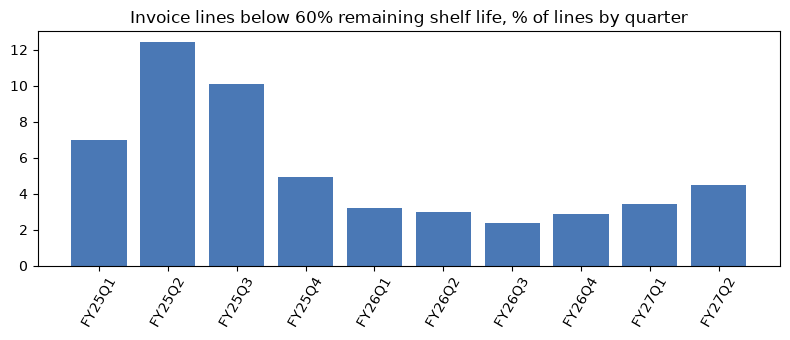

In [29]:
fig, ax = plt.subplots(figsize=(8, 3.5)); ax.bar(t7.index, t7['share_%'], color='#4a78b5'); ax.set_title('Invoice lines below 60% remaining shelf life, % of lines by quarter'); ax.tick_params(axis='x', rotation=60); plt.tight_layout(); plt.show()
b7[['src_row', 'invoice_no', 'invoice_date', 'cnf_code', 'stockist_code', 'sku_code', 'batch_no', 'expiry', 'days_left', 'rsl', 'rsl_batch', 'invoiced_qty', 'free_qty', 'net_value_inr']].to_csv(os.path.join(OUT, 'r7_short_dated_lines.csv'), index=False)
SUMMARY.append(dict(rule='R7', rule_text='Remaining shelf life at least 60% at invoice (02 p4 s7.1)', tested=len(p7), not_testable=int(ps.batch_no.isna().sum()), breaches=len(b7), credited_claims=len(b7), credited_inr=round(b7.net_value_inr.sum()),
                    pending_claims=0, pending_inr=0, nature='goods invoiced outside the rule (value of the invoice lines, not a loss)', caveat='Uses shelf_life_months x 30.4375 days; against the batch own life the count is lower (3,412); lines with no batch (not supplied) cannot be tested'))

**Check by hand.** Take a row of `r7_short_dated_lines.csv`: `days_left` should equal batch expiry minus invoice date, and `rsl` = `days_left` / (shelf-life months x 30.44). In `sku_master.csv` look up the SKU's `shelf_life_months`.

In [30]:
d_ = ((p7.expiry.values.astype('datetime64[D]') - p7.invoice_date.values.astype('datetime64[D]')).astype('int64'))
sm = p7.shelf_m.values
assert int(((d_ < 0.60 * sm * 30.4375) | (d_ < 60)).sum()) == len(b7)
assert (p7.days_left == d_).all() and p7.days_left.notna().all()
assert len(p7) == int(ps.batch_no.notna().sum())
assert p7.shelf_m.notna().all() and p7.expiry.notna().all() and p7.rsl.notna().all()
assert len(b7) > 0
print('R7 CHECKS PASSED:', len(b7), 'short-dated lines')

R7 CHECKS PASSED: 4866 short-dated lines


## R8. Free goods at most 3% of the quarter's primary sales (`02` p2 sections 4.3 and 4.4)

**The rule.** "The value of free goods issued under all schemes in a quarter, at PTS, must not exceed 3% of the quarter's primary sales value." Schemes above the cap "also need the CFO's approval."

**How we test it.** Per financial-year quarter: free goods at PTS (`free_qty` x `pts_inr`) divided by primary sales (`net_value_inr`). The part above 3% is the excess.

**What the QBR already says.** "Free goods have been above the 3% cap in every quarter since Q3 FY25. Each exception was approved by the CFO." (`06` p2). So this is an **approved** exception, not a hidden breach. What it adds is the **rupee size** of the approved excess.

In [31]:
ps8 = ps.assign(qtr=fy_quarter(ps.invoice_date), foc=ps.free_qty * ps.pts_inr)
t8 = ps8.groupby('qtr').agg(primary_inr=('net_value_inr', 'sum'), free_goods_inr=('foc', 'sum'))
t8['free_%'] = (t8.free_goods_inr / t8.primary_inr * 100).round(2)
t8['cap_inr'] = 0.03 * t8.primary_inr
t8['over_cap_inr'] = (t8.free_goods_inr - t8.cap_inr).clip(lower=0)
t8['over_cap'] = t8.over_cap_inr > 0
over = t8[t8.over_cap]
print(f'quarters above the 3% cap: {len(over)} of {len(t8)} ({over.index.min()} to {over.index.max()})')
print(f'free goods above the cap, all those quarters together: INR {over.over_cap_inr.sum():,.0f} = INR {over.over_cap_inr.sum() / 1e7:.2f} crore')
print(f'total free goods in the extract: INR {t8.free_goods_inr.sum():,.0f} = {t8.free_goods_inr.sum() / t8.primary_inr.sum() * 100:.2f}% of primary')
t8.round(0).assign(**{'free_%': t8['free_%']})

quarters above the 3% cap: 7 of 10 (FY25Q3 to FY27Q1)
free goods above the cap, all those quarters together: INR 39,540,773 = INR 3.95 crore
total free goods in the extract: INR 174,842,472 = 3.42% of primary


,primary_inr,free_goods_inr,free_%,cap_inr,over_cap_inr,over_cap
qtr,,,,,,
FY25Q1,462680914.0,5463727.0,1.18,13880427.0,0.0,False
FY25Q2,490341525.0,6106296.0,1.25,14710246.0,0.0,False
FY25Q3,565186612.0,27982870.0,4.95,16955598.0,11027272.0,True
FY25Q4,532039192.0,24929698.0,4.69,15961176.0,8968522.0,True
FY26Q1,525222471.0,24603470.0,4.68,15756674.0,8846796.0,True
FY26Q2,518390011.0,19423449.0,3.75,15551700.0,3871749.0,True
FY26Q3,504177839.0,17473489.0,3.47,15125335.0,2348154.0,True
FY26Q4,493657862.0,15745604.0,3.19,14809736.0,935868.0,True
FY27Q1,513571835.0,18949567.0,3.69,15407155.0,3542412.0,True


**Check:** **7 of 10** quarters are above the cap, **FY25Q3 to FY27Q1**; FY25Q1, FY25Q2 and FY27Q2 are under. FY27Q1 is **3.69%**, which is the QBR figure. The excess adds up to about **INR 3.95 crore** (INR 39.5 million) across those seven quarters.

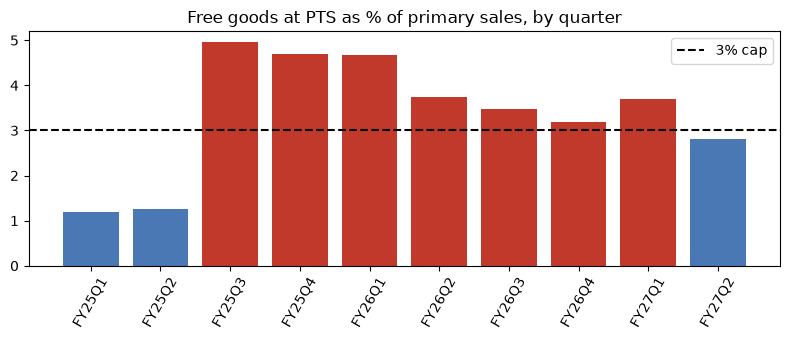

R8 CHECKS PASSED: 7 quarters above cap


In [32]:
fig, ax = plt.subplots(figsize=(8, 3.5)); ax.bar(t8.index, t8['free_%'], color=['#c0392b' if o else '#4a78b5' for o in t8.over_cap]); ax.axhline(3, color='k', ls='--', label='3% cap'); ax.legend()
ax.set_title('Free goods at PTS as % of primary sales, by quarter'); ax.tick_params(axis='x', rotation=60); plt.tight_layout(); plt.show()
t8.reset_index().to_csv(os.path.join(OUT, 'r8_free_goods_by_quarter.csv'), index=False)
SUMMARY.append(dict(rule='R8', rule_text='Free goods at most 3% of quarter primary (02 p2 s4.4)', tested=len(t8), not_testable=0, breaches=len(over), credited_claims=len(over), credited_inr=round(over.over_cap_inr.sum()),
                    pending_claims=0, pending_inr=0, nature='free goods above the cap (CFO-approved each quarter per 06 p2; this is the rupee size of the approved excess)', caveat='breaches = quarters, not claims; approvals themselves are not in the data'))
assert abs(t8.loc['FY27Q1', 'free_%'] - 3.69) < 0.005                         # the QBR figure
assert abs(t8.free_goods_inr.sum() - float((ps.free_qty * ps.pts_inr).sum())) < 1
n_ = sum(1 for q in t8.index if t8.loc[q, 'free_goods_inr'] > 0.03 * t8.loc[q, 'primary_inr'])
assert n_ == len(over)
print('R8 CHECKS PASSED:', len(over), 'quarters above cap')

## R9. Quarter-end schemes: dates, SKUs, terms and minimum order (`02` p2 section 4.2; Annexure B p5 to 6)

**The rules.** Each circular "is valid from the 22nd of the last month of the quarter until the last day of that month." It covers listed SKUs (Tier A or Tier B) with terms **10 + 1** or **10 + 2** free. "The minimum order for every quarter-end scheme is 1.5 times the stockist's average monthly purchase of that SKU over the previous three months."

**Five tests, each on lines that carry a scheme code** (`NO_SCHEME` is our label for lines with none; see the data dictionary):
1. the scheme code is in the Annexure B register;
2. the invoice date is inside the 22nd-to-month-end window of the code's quarter;
3. the SKU is on that tier's list;
4. free packs follow the terms (10+1 or 10+2, proportional);
5. the order is at least 1.5 x the stockist's average monthly purchase of that SKU in the **previous three calendar months**.

Test 5 is the one that needs a judgement about "average monthly purchase". We count packs invoiced for that stockist and SKU in each of the three months before the invoice month (a month with no purchase counts as 0), and divide by 3. It only runs when all three months are inside the extract (from July 2024). Treat it as **lower confidence**.

In [33]:
REG = ['QS-FY25Q1-A', 'QS-FY25Q2-A', 'QS-FY25Q3-A', 'QS-FY25Q3-B', 'QS-FY25Q4-A', 'QS-FY25Q4-B', 'QS-FY26Q1-A', 'QS-FY26Q1-B', 'QS-FY26Q2-A', 'QS-FY26Q2-B',
       'QS-FY26Q3-A', 'QS-FY26Q3-B', 'QS-FY26Q4-A', 'QS-FY26Q4-B', 'QS-FY27Q1-A', 'QS-FY27Q1-B', 'QS-FY27Q2-A', 'QS-FY27Q2-B']        # Annexure B, 02 p5-6 (18 codes)
TIER_A = ['PFL1001', 'PFL1002', 'PFL1003', 'PFL1101', 'PFL1102', 'PFL1103', 'PFL1105', 'PFL1202', 'PFL1301', 'PFL1303']
TIER_B = ['PFL1004', 'PFL1104', 'PFL1201', 'PFL1302', 'PFL1401']
sc = ps[ps.scheme_code.ne('NO_SCHEME')].copy()
sc['code_q'] = sc.scheme_code.str.slice(3, 9); sc['tier'] = sc.scheme_code.str[-1]
def window(cq):
    fy = 2000 + int(cq[2:4]); qn = int(cq[5]); mth = [6, 9, 12, 3][qn - 1]; yr = fy - 1 if qn < 4 else fy
    return pd.Timestamp(yr, mth, 22), pd.Timestamp(yr, mth, 1) + pd.offsets.MonthEnd(0)
W = {c: window(c) for c in sc.code_q.unique()}
sc['in_register'] = sc.scheme_code.isin(REG)
sc['in_window'] = [(W[c][0] <= d <= W[c][1]) for c, d in zip(sc.code_q, sc.invoice_date)]
sc['sku_on_list'] = np.where(sc.tier.eq('A'), sc.sku_code.isin(TIER_A), sc.sku_code.isin(TIER_B))
print('lines with a scheme code:', len(sc), '| distinct codes:', sc.scheme_code.nunique())
print('1. code in the Annexure B register   : breaches', int((~sc.in_register).sum()))
print('2. invoice date inside the window     : breaches', int((~sc.in_window).sum()))
print('3. SKU on the tier list               : breaches', int((~sc.sku_on_list).sum()))
print('lines with free goods but NO scheme code:', int((ps.free_qty.gt(0) & ps.scheme_code.eq('NO_SCHEME')).sum()))

lines with a scheme code: 12610 | distinct codes: 18
1. code in the Annexure B register   : breaches 0
2. invoice date inside the window     : breaches 0
3. SKU on the tier list               : breaches 0
lines with free goods but NO scheme code: 0


**Check:** **12,610** scheme lines, **18** codes. Tests 1, 2 and 3 all show **0** breaches. There are also **0** lines with free goods and no scheme code. Scheme discipline on dates, codes and SKU lists is clean.

In [34]:
# 4. free-goods terms: free packs per ORDER LINE (invoice_no + sku_code) vs invoiced packs x k/10, with k = 2 for Tier A from FY25Q3 and 1 otherwise (Annexure B)
sc['k'] = np.where(sc.tier.eq('A') & (sc.code_q >= 'FY25Q3'), 2, 1)
ol9 = sc[sc.free_qty > 0].groupby(['invoice_no', 'sku_code']).agg(invoiced=('invoiced_qty', 'sum'), free=('free_qty', 'sum'), k=('k', 'first'), code=('scheme_code', 'first')).reset_index()
ol9['expected'] = np.round(ol9.invoiced * ol9.k / 10)
off = ol9[ol9.free != ol9.expected]
print('4. order lines with free goods:', len(ol9), '| free packs = invoiced x k/10 (rounded):', len(ol9) - len(off), '| off by one or more:', len(off))

4. order lines with free goods: 10288 | free packs = invoiced x k/10 (rounded): 10264 | off by one or more: 24


**Check:** about **10,288** order lines; **all but about 24** follow the terms. So the 10+1 and 10+2 terms are applied consistently.

In [35]:
# 5. minimum order: ordered packs on the scheme order line vs 1.5 x average monthly purchase in the 3 previous months
ps9 = ps.assign(ym=ps.invoice_date.dt.to_period('M'))
mon = ps9.groupby(['stockist_code', 'sku_code', 'ym']).invoiced_qty.sum()
first_month = ps9.ym.min()
sl = ps9[ps9.scheme_code.ne('NO_SCHEME')].groupby(['invoice_no', 'sku_code']).agg(stockist_code=('stockist_code', 'first'), ym=('ym', 'first'), invoice_date=('invoice_date', 'min'),
        ordered=('ordered_qty', 'max'), invoiced=('invoiced_qty', 'sum'), free=('free_qty', 'sum'), pts=('pts_inr', 'first'), scheme_code=('scheme_code', 'first')).reset_index()
def avg3(r):
    prev = [r.ym - 1, r.ym - 2, r.ym - 3]
    if prev[2] < first_month: return np.nan
    return sum(mon.get((r.stockist_code, r.sku_code, m), 0) for m in prev) / 3
sl['avg3'] = sl.apply(avg3, axis=1)
sl['r9_testable'] = sl.avg3.notna() & (sl.invoiced > 0)
sl['r9_below_moq'] = sl.r9_testable & (sl.ordered < 1.5 * sl.avg3)
sl['free_inr'] = sl.free * sl.pts
b9 = sl[sl.r9_below_moq]
print('scheme order lines:', len(sl), '| testable (supplied, 3 earlier months in the extract):', int(sl.r9_testable.sum()))
print('5. ordered below 1.5 x average monthly purchase:', len(b9), f'({len(b9) / sl.r9_testable.sum() * 100:.0f}% of testable)')
print(f'   free goods on those orders: {int(b9.free.sum()):,} packs = INR {b9.free_inr.sum():,.0f}')
print('   ratio of ordered to average (testable lines): median', round((sl[sl.r9_testable].ordered / sl[sl.r9_testable].avg3.replace(0, np.nan)).median(), 2))

scheme order lines: 11967 | testable (supplied, 3 earlier months in the extract): 9452
5. ordered below 1.5 x average monthly purchase: 5490 (58% of testable)
   free goods on those orders: 821,489 packs = INR 64,885,646
   ratio of ordered to average (testable lines): median 1.39


**Check:** about **9,450** testable scheme order lines; about **5,490** (58%) ordered under 1.5 x the average. The median ratio is about 1.4, so many orders sit just under the line.

**Reading it with care.** A rule that is missed by 58% of lines, with a median very near the limit, may mean the client counts the average differently (for example over a different three months, or per quarter). Treat this as **a question for the client**, not a proven breach. The date, code, SKU-list and terms tests are clean.

In [36]:
b9[['invoice_no', 'invoice_date', 'stockist_code', 'sku_code', 'scheme_code', 'ordered', 'avg3', 'invoiced', 'free', 'free_inr']].to_csv(os.path.join(OUT, 'r9_below_minimum_order.csv'), index=False)
SUMMARY.append(dict(rule='R9', rule_text='Quarter-end scheme dates, SKUs, terms, minimum order (02 p2 s4.2, Annex B)', tested=int(sl.r9_testable.sum()), not_testable=int((~sl.r9_testable).sum()), breaches=len(b9),
                    credited_claims=len(b9), credited_inr=round(b9.free_inr.sum()), pending_claims=0, pending_inr=0, nature='free goods given on orders below the minimum (LOWER CONFIDENCE: how the 3-month average is counted is our reading)',
                    caveat='Tests 1 to 4 (code, window, SKU list, terms) show no or almost no breaches; the minimum-order test is sensitive to how the average is counted'))

In [37]:
# independent check of the minimum-order test, plain loops over the order lines
tot, n_t, n_b = {}, 0, 0
for r in ps.itertuples():
    k = (r.stockist_code, r.sku_code, r.invoice_date.year * 12 + r.invoice_date.month); tot[k] = tot.get(k, 0) + r.invoiced_qty
fm = ps.invoice_date.min().year * 12 + ps.invoice_date.min().month
for r in sl.itertuples():
    m = r.invoice_date.year * 12 + r.invoice_date.month
    if m - 3 < fm or r.invoiced <= 0: continue
    a = sum(tot.get((r.stockist_code, r.sku_code, m - j), 0) for j in (1, 2, 3)) / 3; n_t += 1
    if r.ordered < 1.5 * a: n_b += 1
assert (n_t, n_b) == (int(sl.r9_testable.sum()), len(b9)), (n_t, n_b, int(sl.r9_testable.sum()), len(b9))
assert int((~sc.in_register).sum()) == 0 and int((~sc.in_window).sum()) == 0 and int((~sc.sku_on_list).sum()) == 0
print('R9 CHECKS PASSED:', n_t, 'testable order lines,', n_b, 'below the minimum')

R9 CHECKS PASSED: 9452 testable order lines, 5490 below the minimum


## R10. C&F stock topped up to two months; one shipment at most 1.2 months (`03` p3 section 2.2)

**The rule.** "The Agent's stock is topped up to two months of its allocated volume, and one shipment does not exceed 1.2 months of allocated volume."

**How we test it.** *Months of cover* = packs on hand / `avg_monthly_outward_packs` (the rolling 3-month average outward, `01` p3 section 5.5), per C&F, SKU and snapshot date, adding the batches. Above 2 months is stock beyond the norm; the value of the packs above 2 months at PTS is the **excess stock**.

**The 1.2-month shipment limit cannot be tested**: the extract has no shipments from the plant to the C&F.

**The conflicting snapshot rows.** In 831 groups the same date, C&F, SKU and batch has two different quantities (open client question). We add both (as the QBR does, see 3.6) and, as a check, use only the larger one.

In [38]:
sn = load('cnf_stock_snapshot')
h = sn[sn.batch_no.notna()].copy()
kk = ['snapshot_date', 'cnf_code', 'sku_code']
def cover(df, how):
    if how == 'larger':
        df = df.groupby(kk + ['batch_no'], as_index=False).agg(qty_on_hand_packs=('qty_on_hand_packs', 'max'), avg_monthly_outward_packs=('avg_monthly_outward_packs', 'first'))
    g = df.groupby(kk).agg(qty=('qty_on_hand_packs', 'sum'), avg=('avg_monthly_outward_packs', 'max')).reset_index()
    g['pts'] = g.sku_code.map(sku.set_index('sku_code').pts_inr)
    g['cover'] = g.qty / g.avg.replace(0, np.nan)
    g['excess_inr'] = (g.qty - 2 * g.avg).clip(lower=0) * g.pts
    return g
G = cover(h, 'sum'); G2 = cover(h, 'larger')
city = sn.drop_duplicates('cnf_code').set_index('cnf_code').cnf_city
LAST = pd.Timestamp('2026-09-30')
L = G[G.snapshot_date.eq(LAST)]
print('C&F x SKU stocks measured:', len(G), '| above 2 months of cover:', int((G.cover > 2).sum()), f'({(G.cover > 2).mean() * 100:.0f}%) | below 1 month:', int((G.cover < 1).sum()))
print(f'at the last snapshot, {LAST.date()}: stock above the 2-month norm = INR {L.excess_inr.sum():,.0f} = INR {L.excess_inr.sum() / 1e7:.1f} crore')
print('   using only the larger of conflicting rows instead:', f'INR {G2[G2.snapshot_date.eq(LAST)].excess_inr.sum() / 1e7:.1f} crore')
tt = G[G.snapshot_date.eq(LAST)].groupby('cnf_code').agg(skus=('sku_code', 'nunique'), median_cover_months=('cover', 'median'), excess_inr=('excess_inr', 'sum')).round(2)
tt.insert(0, 'city', city); tt

C&F x SKU stocks measured: 2754 | above 2 months of cover: 1761 (64%) | below 1 month: 231
at the last snapshot, 2026-09-30: stock above the 2-month norm = INR 49,607,144 = INR 5.0 crore
   using only the larger of conflicting rows instead: INR 4.3 crore


,city,skus,median_cover_months,excess_inr
cnf_code,,,,
CF-E01,Kolkata,29,5.80,24085235.3
CF-N01,Gurugram,29,2.59,2620596.3
CF-N02,Lucknow,13,1.20,0.0
CF-S01,Chennai,27,3.62,8344655.6
CF-S02,Hyderabad,29,3.38,7353954.7
CF-W01,Bhiwandi,31,3.25,7202701.9


**Check:** about **2,750** C&F x SKU stocks, **64%** above 2 months; at 30 Sep 2026 the excess is about **INR 5.0 crore** (about 4.2 crore at 30 Jun 2026). At 30 Sep 2026 the median cover is **5.8 months at Kolkata (CF-E01)**, which holds about INR 2.4 crore of the excess, and **1.2 months at Lucknow (CF-N02)**, which holds stock in only 13 of the 36 SKUs. This matches the QBR minutes: "Kolkata had requested a hold on replenishment and Lucknow an increase" (`06` p4, Item 3).

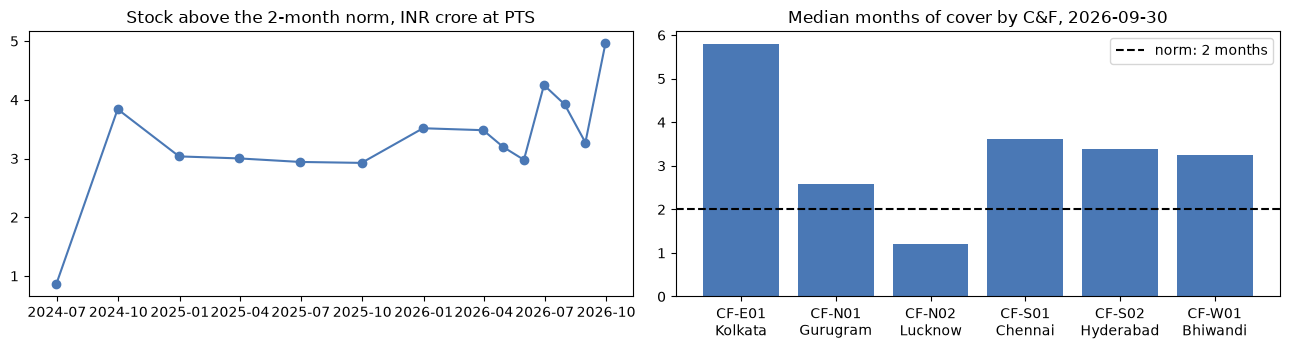

In [39]:
trend = G.groupby('snapshot_date').agg(share_above_2m=('cover', lambda c: (c > 2).mean()), excess_inr=('excess_inr', 'sum'))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].plot(trend.index, trend.excess_inr / 1e7, marker='o', color='#4a78b5'); ax[0].set_title('Stock above the 2-month norm, INR crore at PTS')
piv = G[G.snapshot_date.eq(LAST)].groupby('cnf_code').cover.median(); ax[1].bar([f'{c}\n{city[c]}' for c in piv.index], piv.values, color='#4a78b5'); ax[1].axhline(2, color='k', ls='--', label='norm: 2 months'); ax[1].legend(); ax[1].set_title(f'Median months of cover by C&F, {LAST.date()}')
plt.tight_layout(); plt.show()
G.assign(city=G.cnf_code.map(city)).to_csv(os.path.join(OUT, 'r10_cover_by_cnf_sku_date.csv'), index=False)
SUMMARY.append(dict(rule='R10', rule_text='C&F stock topped up to 2 months, shipment at most 1.2 months (03 p3 s2.2)', tested=len(G), not_testable=0, breaches=int((G.cover > 2).sum()), credited_claims=int((G.cover > 2).sum()), credited_inr=round(L.excess_inr.sum()),
                    pending_claims=0, pending_inr=0, nature='inventory above the 2-month norm at the last snapshot (value of excess packs at PTS; stock, not a loss)', caveat='The 1.2-month shipment limit is not testable (no shipment data); snapshot conflicts add both quantities (the QBR basis); credited_inr is the 30 Sep 2026 position, breaches counts C&F x SKU x date'))

In [40]:
cv, avg_, qty_ = {}, {}, {}
for r in h.itertuples():
    k = (r.snapshot_date, r.cnf_code, r.sku_code); qty_[k] = qty_.get(k, 0) + r.qty_on_hand_packs; avg_[k] = max(avg_.get(k, 0), r.avg_monthly_outward_packs)
n_ = sum(1 for k in qty_ if avg_[k] > 0 and qty_[k] / avg_[k] > 2)
assert n_ == int((G.cover > 2).sum()) and len(qty_) == len(G)
assert (G.groupby(kk).size() == 1).all()
assert abs(sum(max(qty_[k] - 2 * avg_[k], 0) * float(sku.set_index('sku_code').pts_inr[k[2]]) for k in qty_ if k[0] == LAST) - L.excess_inr.sum()) < 1
print('R10 CHECKS PASSED:', n_, 'stocks above 2 months')

R10 CHECKS PASSED: 1761 stocks above 2 months


## R11. Short supply: invoice what is available, cancel the balance, keep no back orders (`03` p3 section 2.4)

**The rule.** "If the stock on hand cannot fill an order line in full, the line is invoiced for the quantity available and the balance is cancelled. The stockist reorders. Back orders are not kept."

**What this means for the data.** The rule tells the C&F to *short-supply* when stock runs out, so a short line is **not a breach**. What the data can show is **how much was not supplied**, which is lost sales. We test:
1. no order line is invoiced for **more** than was ordered (that would be a breach);
2. the unfilled quantity per order line (`invoice_no` + `sku_code`), valued at PTS.

**Important: free packs are part of the order.** On scheme lines the `ordered_qty` already includes the free packs: invoiced + free equals ordered on 10,171 of the 10,288 scheme order lines. So supplied packs = `invoiced_qty` + `free_qty`. (An earlier version of our analysis compared invoiced packs alone and wrongly counted these lines as short.)

**Not testable:** whether back orders were kept. The data has no order-level link between a cancelled balance and a later invoice.

In [41]:
o11 = ps.groupby(['invoice_no', 'sku_code']).agg(ordered=('ordered_qty', 'max'), invoiced=('invoiced_qty', 'sum'), free=('free_qty', 'sum'), pts=('pts_inr', 'first'),
        cnf_code=('cnf_code', 'first'), stockist_code=('stockist_code', 'first'), invoice_date=('invoice_date', 'min')).reset_index()
o11['supplied'] = o11.invoiced + o11.free
o11['unfilled'] = (o11.ordered - o11.supplied).clip(lower=0)
o11['unfilled_inr'] = o11.unfilled * o11.pts
o11['status'] = np.select([o11.supplied > o11.ordered, o11.supplied.eq(0), o11.supplied < o11.ordered], ['over-invoiced', 'not supplied', 'short'], 'full')
o11['qtr'] = fy_quarter(o11.invoice_date)
print(o11.status.value_counts().to_dict(), '| order lines:', len(o11))
print('if free packs were ignored (the earlier mistake): short =', int(((o11.invoiced > 0) & (o11.invoiced < o11.ordered)).sum()), '| scheme lines where invoiced + free = ordered:', int(((o11.free > 0) & (o11.supplied == o11.ordered)).sum()), 'of', int((o11.free > 0).sum()))
print(f'unfilled packs: {o11.unfilled.sum():,.0f} of {o11.ordered.sum():,.0f} ordered ({o11.unfilled.sum() / o11.ordered.sum() * 100:.1f}%) = INR {o11.unfilled_inr.sum():,.0f} = INR {o11.unfilled_inr.sum() / 1e7:.1f} crore at PTS')
print(f"   of which lines not supplied at all: {o11[o11.status.eq('not supplied')].unfilled.sum():,.0f} packs = INR {o11[o11.status.eq('not supplied')].unfilled_inr.sum() / 1e7:.1f} crore | partly supplied: {o11[o11.status.eq('short')].unfilled.sum():,.0f} packs = INR {o11[o11.status.eq('short')].unfilled_inr.sum() / 1e7:.1f} crore")
byc = o11.groupby('cnf_code').agg(order_lines=('invoice_no', 'size'), unfilled_inr=('unfilled_inr', 'sum'), ordered_packs=('ordered', 'sum'), unfilled_packs=('unfilled', 'sum'))
byc['unfilled_%'] = (byc.unfilled_packs / byc.ordered_packs * 100).round(1); byc.insert(0, 'city', city); byc.round(0).assign(**{'unfilled_%': byc['unfilled_%']})

{'full': 84304, 'not supplied': 2628, 'short': 254} | order lines: 87186
if free packs were ignored (the earlier mistake): short = 10425 | scheme lines where invoiced + free = ordered: 10171 of 10288
unfilled packs: 3,786,408 of 73,294,896 ordered (5.2%) = INR 383,149,313 = INR 38.3 crore at PTS
   of which lines not supplied at all: 3,596,507 packs = INR 36.7 crore | partly supplied: 189,901 packs = INR 1.6 crore


,city,order_lines,unfilled_inr,ordered_packs,unfilled_packs,unfilled_%
cnf_code,,,,,,
CF-E01,Kolkata,14344,39455143.0,12009927.0,367077.0,3.1
CF-N01,Gurugram,14314,80604344.0,12687621.0,815363.0,6.4
CF-N02,Lucknow,15538,104141187.0,12553125.0,1008702.0,8.0
CF-S01,Chennai,13688,59329705.0,13394571.0,572536.0,4.3
CF-S02,Hyderabad,14592,51912887.0,11329194.0,524557.0,4.6
CF-W01,Bhiwandi,14710,47706048.0,11320458.0,498173.0,4.4


**Check:** **87,186** order lines: **84,304** full, **254** partly supplied, **2,628** not supplied (blank batch), **0** over-invoiced. Ignoring free packs would wrongly show 10,425 short lines.

          ordered   unfilled  unfilled_inr  unfilled_%
qtr                                                   
FY25Q1  6177889.0        0.0           0.0         0.0
FY25Q2  6475465.0        0.0           0.0         0.0
FY25Q3  7620799.0      231.0       22245.0         0.0
FY25Q4  7214359.0        0.0           0.0         0.0
FY26Q1  7157618.0    34436.0     2916729.0         0.5
FY26Q2  7499014.0   406618.0    47114525.0         5.4
FY26Q3  7592136.0   644127.0    70662390.0         8.5
FY26Q4  7634586.0   744270.0    79448389.0         9.7
FY27Q1  7685713.0   703388.0    59928795.0         9.2
FY27Q2  8237317.0  1253338.0   123056240.0        15.2


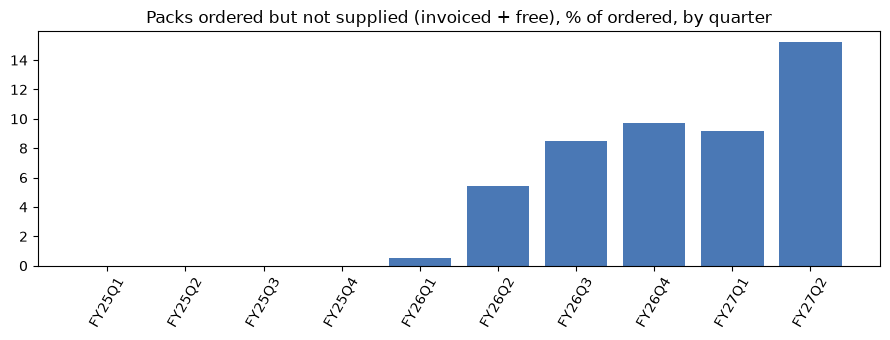

In [42]:
q11 = o11.groupby('qtr').agg(ordered=('ordered', 'sum'), unfilled=('unfilled', 'sum'), unfilled_inr=('unfilled_inr', 'sum')); q11['unfilled_%'] = (q11.unfilled / q11.ordered * 100).round(1)
print(q11.round(0).assign(**{'unfilled_%': q11['unfilled_%']}).to_string())
fig, ax = plt.subplots(figsize=(9, 3.5)); ax.bar(q11.index, q11['unfilled_%'], color='#4a78b5'); ax.set_title('Packs ordered but not supplied (invoiced + free), % of ordered, by quarter'); ax.tick_params(axis='x', rotation=60); plt.tight_layout(); plt.show()

**Check:** the unfilled share is **0%** through FY25, **0.5%** in FY26 Q1, then **5.4%, 8.5%, 9.7%, 9.2%** (FY26 Q2 to FY27 Q1), and **15.2%** in FY27 Q2. FY27 Q1 equals the QBR fill rate: 100% - 9.2% = **90.8%** (QBR 90.9%). By C&F, Lucknow (CF-N02) is highest at about 8%, Kolkata (CF-E01) lowest at about 3% (see the table above).

In [43]:
o11[o11.status.isin(['short', 'not supplied'])].to_csv(os.path.join(OUT, 'r11_unfilled_order_lines.csv'), index=False)
SUMMARY.append(dict(rule='R11', rule_text='Short supply: invoice what is available, cancel the balance (03 p3 s2.4)', tested=len(o11), not_testable=0, breaches=int((o11.status == 'over-invoiced').sum()), credited_claims=int(o11.status.isin(['short', 'not supplied']).sum()),
                    credited_inr=round(o11.unfilled_inr.sum()), pending_claims=0, pending_inr=0, nature='unfilled order value at PTS (lost sales over the whole extract; short supply is allowed by the rule, so this is not a breach)',
                    caveat='Back orders cannot be tested; ordered_qty is read per order line (invoice_no + sku_code) and includes free packs on scheme lines'))

In [44]:
ob = {}
for r in ps.itertuples():
    k = (r.invoice_no, r.sku_code); a = ob.setdefault(k, [np.nan, 0.0])
    if not np.isnan(r.ordered_qty): a[0] = r.ordered_qty
    a[1] += r.invoiced_qty + r.free_qty
assert len(ob) == len(o11)
assert sum(max(o - i, 0) for o, i in ob.values()) == o11.unfilled.sum()
assert int((o11.status == 'over-invoiced').sum()) == 0 and o11.ordered.notna().all()
assert dict(o11.status.value_counts()) == {'full': 84304, 'short': 254, 'not supplied': 2628}, dict(o11.status.value_counts())
print('R11 CHECKS PASSED')

R11 CHECKS PASSED


## R12. Claim number format `CLM-yymm-nnnnn` (`03` p3 section 2.6)

**The rule.** "Log every claim in the claims register when it arrives, with a claim number in the format CLM-yymm-nnnnn." So `yymm` is the year and month the claim arrived.

**How we test it.** (a) every number matches the format; (b) numbers are unique; (c) the `yymm` agrees with the month of `claim_date`.

**Why it matters.** (c) is what tells us whether `claim_date` can be trusted. The R1 section found that for some claims the two disagree.

In [45]:
ok_fmt = ec.claim_no.str.fullmatch(r'CLM-\d{4}-\d{5}')
ym_no = ec.claim_no.str.slice(4, 8)
ym_dt = ec.claim_date.dt.strftime('%y%m')
mis = ec[ym_no != ym_dt].copy()
mis['lag_months'] = (mis.claim_date.dt.year * 12 + mis.claim_date.dt.month) - (2000 + mis.claim_no.str.slice(4, 6).astype(int)) * 12 - mis.claim_no.str.slice(6, 8).astype(int)
mis['r12_inr'] = np.where(mis.status.eq('Credited'), mis.credit_value_inr.fillna(0), np.where(mis.status.eq('Pending'), mis.claim_value_derived_inr, 0.0))
print('claim numbers in the right format:', int(ok_fmt.sum()), 'of', len(ec), '| duplicate numbers:', int(ec.claim_no.duplicated().sum()))
print('claim number month differs from claim_date month:', len(mis), '| claim_date is LATER by (months):', mis.lag_months.value_counts().sort_index().to_dict(), '| earlier:', int((mis.lag_months < 0).sum()))
print('   by status:', mis.status.value_counts().to_dict(), '| by type:', mis.claim_type.value_counts().to_dict())
print('   how many of these are R1 window breaches:', int(mis.claim_no.isin(ec[ec.r1_breach].claim_no).sum()))

claim numbers in the right format: 4503 of 4503 | duplicate numbers: 0
claim number month differs from claim_date month: 84 | claim_date is LATER by (months): {1: 6, 2: 8, 3: 17, 4: 11, 5: 17, 6: 14, 7: 6, 8: 4, 9: 1} | earlier: 0
   by status: {'Credited': 55, 'Pending': 29} | by type: {'Near expiry': 51, 'Expired': 33}
   how many of these are R1 window breaches: 81


**Check:** format OK for all **4,503**, no duplicates. **84** claims have a number month earlier than the `claim_date` month, by 1 to 9 months, never later (55 Credited, 29 Pending; 51 Near expiry, 33 Expired). **81** of them are R1 breaches.

**Reading it.** `claim_date` is later than the claim's own number for these 84 claims. Either the register's date is the date of processing, not of arrival, or the number was issued earlier. This is a **client question** and it decides whether those 81 R1 breaches are real.

In [46]:
mis[['src_row', 'claim_no', 'claim_date', 'lag_months', 'claim_type', 'status', 'expiry_date_as_claimed', 'credit_note_date', 'r12_inr']].to_csv(os.path.join(OUT, 'r12_claim_number_vs_date.csv'), index=False)
c12, p12 = mis[mis.status.eq('Credited')], mis[mis.status.eq('Pending')]
SUMMARY.append(dict(rule='R12', rule_text='Claim number format CLM-yymm-nnnnn (03 p3 s2.6)', tested=len(ec), not_testable=0, breaches=len(mis), credited_claims=len(c12), credited_inr=round(c12.r12_inr.sum()), pending_claims=len(p12), pending_inr=round(p12.r12_inr.sum()),
                    nature='record-keeping: the claim number month and claim_date disagree (decides how far to trust R1)', caveat='Format is correct for every claim; the disagreement is only between the number month and claim_date'))
assert ok_fmt.all() and not ec.claim_no.duplicated().any()
n_ = sum(1 for n, d in zip(ec.claim_no, ec.claim_date) if n[4:8] != d.strftime('%y%m'))
assert n_ == len(mis) and (mis.lag_months > 0).all()
print('R12 CHECKS PASSED:', n_, 'claims where the number month differs from the claim date')

R12 CHECKS PASSED: 84 claims where the number month differs from the claim date


## R13. No scheme to a stockist holding more than 2.5 months of average secondary stock (`02` p3 section 4.5)
**Not testable.** The company has no secondary sales or stockist stock data (`01` p2 section 3; Commercial Finance's note in `02` section 4.5: "SSS is not received for this portfolio"). We record this as a finding about the control, not a gap in our analysis: the rule exists, and nobody can check it.

In [47]:
SUMMARY.append(dict(rule='R13', rule_text='No scheme where stockist holds > 2.5 months secondary (02 p3 s4.5)', tested=0, not_testable=0, breaches=0, credited_claims=0, credited_inr=0, pending_claims=0, pending_inr=0,
                    nature='NOT TESTABLE: no secondary sales or stockist stock data', caveat='The rule exists but the company cannot check it (SSS not received, 02 s4.5 note)'))

## What 4.1 has and has not done yet
Done: **R1 to R12** (R13 is not testable). The summary table at the end is `data-clean/audit/rules/rules_summary.csv`. Next, Step 4.2 tests the beliefs and voice notes.

In [48]:
pd.DataFrame(SUMMARY).to_csv(os.path.join(OUT, 'rules_summary.csv'), index=False)
pd.DataFrame(SUMMARY)

,rule,rule_text,tested,not_testable,breaches,credited_claims,credited_inr,pending_claims,pending_inr,dependent_breaches,dependent_credited_inr,nature,caveat
0,R1,Claim windows (02 p3 s5.2),4428,75,519,446,4811067,62,1225892,81.0,959200.0,money paid outside the rule,No approval/exception column in the data; brea...
1,R3,Quantity claimed within packs invoiced incl. f...,3532,971,44,40,179438,4,2777,NaN,NaN,money paid outside the rule (value of the exce...,Only claims on batches inside batch_master; 97...
2,R4,No earlier claim on the same stockist and batc...,4503,0,98,61,1114437,12,345693,NaN,NaN,money paid outside the rule (probable duplicat...,A repeat with a different quantity may be a ge...
3,R6,Credit note within 30 days of receipt (02 p4 s...,4472,0,3244,3115,54125894,129,3378987,NaN,NaN,"service delay, not a money loss (value of late...",claim_date used as the date of receipt; pendin...
4,R2,Invoice reference or Area Manager approval (02...,4503,0,861,798,13274550,63,1434690,NaN,NaN,approval not evidenced (weakest kind of findin...,The register has no approval column; only the ...
5,R5,Claims valued at PTS (02 p4 s5.7),4112,0,327,327,458441,0,0,NaN,NaN,valuation difference: credit note is LOWER tha...,PTS on the claim date cannot be tested (one pr...
6,R7,Remaining shelf life at least 60% at invoice (...,90435,2628,4866,4866,234980798,0,0,NaN,NaN,goods invoiced outside the rule (value of the ...,Uses shelf_life_months x 30.4375 days; against...
7,R8,Free goods at most 3% of quarter primary (02 p...,10,0,7,7,39540773,0,0,NaN,NaN,free goods above the cap (CFO-approved each qu...,"breaches = quarters, not claims; approvals the..."
8,R9,"Quarter-end scheme dates, SKUs, terms, minimum...",9452,2515,5490,5490,64885646,0,0,NaN,NaN,free goods given on orders below the minimum (...,"Tests 1 to 4 (code, window, SKU list, terms) s..."
9,R10,"C&F stock topped up to 2 months, shipment at m...",2754,0,1761,1761,49607144,0,0,NaN,NaN,inventory above the 2-month norm at the last s...,The 1.2-month shipment limit is not testable (...
